# Example 8.3 — Statistical Comparison of Five Methods

**Book:** Synthesis of Four-Bar Linkages with GA and Neural Networks  
**Chapter 8** | Google Colab

## Common functions

In [1]:
import numpy as np
from numpy import cos, sin, pi, sqrt, arctan2, nan, linspace, array, where, maximum, isfinite

def fourbar_coupler(a, b, c, d, th2, p=35.0, delta=pi/5):
    K1 = d / a
    K2 = d / c
    K3 = (a**2 - b**2 + c**2 + d**2) / (2 * a * c)

    A = cos(th2) - K1 - K2 * cos(th2) + K3
    B = -2 * sin(th2)
    C = K1 - (K2 + 1) * cos(th2) + K3
    disc = B**2 - 4 * A * C

    th4 = where(disc >= 0, 2 * arctan2(-B - sqrt(maximum(disc, 0)), 2 * A), nan)

    K4 = d / b
    K5 = (c**2 - d**2 - a**2 - b**2) / (2 * a * b)
    A2 = cos(th2) - K1 + K4 * cos(th2) + K5
    B2 = -2 * sin(th2)
    C2 = K1 + (K4 - 1) * cos(th2) + K5
    disc2 = B2**2 - 4 * A2 * C2

    th3 = where(disc >= 0, 2 * arctan2(-B2 - sqrt(maximum(disc2, 0)), 2 * A2), nan)

    x_coupler = a * cos(th2) + p * cos(th3 + delta)
    y_coupler = a * sin(th2) + p * sin(th3 + delta)
    return x_coupler, y_coupler

def hausdorff(Cx, Cy, Px, Py):
    m = isfinite(Cx)
    if not m.any():
        return 1e6
    D = sqrt((Cx[m, None] - Px)**2 + (Cy[m, None] - Py)**2)
    return max(D.min(axis=0).max(), D.min(axis=1).max())

t = linspace(0, 2 * pi, 20)
Px = 45 + 22 * cos(t)
Py = 25 + 18 * sin(t)

th2v = linspace(0, 2 * pi, 72)
D_F = 85.0

LB = array([10.0, 10.0, 10.0])
UB = array([80.0, 60.0, 80.0])

def fitness(p):
    return hausdorff(*fourbar_coupler(p[0], p[1], p[2], D_F, th2v), Px, Py)

## The five algorithms

In [2]:
from numpy.random import seed, rand, randn, choice
from numpy import clip, zeros, argmin

def run_random(seed_val):
    seed(seed_val)
    return min([fitness(LB + rand(3) * (UB - LB)) for _ in range(500)])

def run_ga(seed_val):
    seed(seed_val)
    N = 20
    NG = 25
    pm = 0.15
    pc = 0.8
    pop = LB + rand(N, 3) * (UB - LB)

    for _ in range(NG):
        fit = array([fitness(p) for p in pop])
        new = []
        for _ in range(N):
            i, j = choice(N, 2, replace=False)
            p1 = pop[i] if fit[i] < fit[j] else pop[j]
            i, j = choice(N, 2, replace=False)
            p2 = pop[i] if fit[i] < fit[j] else pop[j]

            alpha = rand(3)
            c = alpha * p1 + (1.0 - alpha) * p2
            if rand() < pm:
                c += randn(3) * 2.0
            new.append(clip(c, LB, UB))
        pop = array(new)
    return min([fitness(p) for p in pop])

def run_de(seed_val):
    seed(seed_val)
    N = 15
    NG = 25
    F = 0.8
    CR = 0.9
    pop = LB + rand(N, 3) * (UB - LB)

    for _ in range(NG):
        for i in range(N):
            idxs = list(range(N))
            idxs.remove(i)
            a_, b_, c_ = pop[choice(idxs, 3, replace=False)]
            mut = clip(a_ + F * (b_ - c_), LB, UB)
            cross = rand(3) < CR
            if not cross.any():
                cross[choice(3)] = True
            trial = where(cross, mut, pop[i])
            if fitness(trial) < fitness(pop[i]):
                pop[i] = trial
    return min([fitness(p) for p in pop])

def run_pso(seed_val):
    seed(seed_val)
    N = 20
    NI = 25
    w = 0.7
    c1 = 1.5
    c2 = 1.5
    pos = LB + rand(N, 3) * (UB - LB)
    vel = zeros((N, 3))
    pb = pos.copy()
    pb_f = array([fitness(p) for p in pos])
    gb = pb[argmin(pb_f)].copy()

    for _ in range(NI):
        r1 = rand(N, 3)
        r2 = rand(N, 3)
        vel = w * vel + c1 * r1 * (pb - pos) + c2 * r2 * (gb - pos)
        pos = clip(pos + vel, LB, UB)
        fn = array([fitness(p) for p in pos])
        bt = fn < pb_f
        pb[bt] = pos[bt]
        pb_f[bt] = fn[bt]
        gb = pb[argmin(pb_f)].copy()
    return fitness(gb)

def run_ga_hc(seed_val):
    seed(seed_val)
    N = 20
    NG = 25
    pop = LB + rand(N, 3) * (UB - LB)

    for _ in range(NG):
        fit = array([fitness(p) for p in pop])
        new = []
        for _ in range(N):
            i, j = choice(N, 2, replace=False)
            p1 = pop[i] if fit[i] < fit[j] else pop[j]
            i, j = choice(N, 2, replace=False)
            p2 = pop[i] if fit[i] < fit[j] else pop[j]

            alpha = rand(3)
            c = alpha * p1 + (1.0 - alpha) * p2
            if rand() < 0.15:
                c += randn(3) * 2.0
            c = clip(c, LB, UB)
            f0 = fitness(c)

            for k in range(3):
                for delta in [1.0, -1.0]:
                    cc = c.copy()
                    cc[k] = clip(cc[k] + delta, LB[k], UB[k])
                    if fitness(cc) < f0:
                        c = cc
                        f0 = fitness(cc)
            new.append(c)
        pop = array(new)
    return min([fitness(p) for p in pop])

print("Algorithms defined OK")

Algorithms defined OK


## Statistical comparison (5 seeds × 5 methods)

In [3]:
SEEDS = [7, 13, 21, 42, 99]
methods = [
    ("Random", run_random),
    ("GA", run_ga),
    ("DE", run_de),
    ("PSO", run_pso),
    ("GA+HC", run_ga_hc)
]

print(f"{'Method':<12} {'Mean':>8} {'Std':>8} {'Min':>8} {'Max':>8}")
print("-" * 50)

results_all = {}
for name, fn in methods:
    res = array([fn(s) for s in SEEDS])
    results_all[name] = res
    print(f"{name:<12} {res.mean():>8.2f} {res.std():>8.2f} {res.min():>8.2f} {res.max():>8.2f}")

Method           Mean      Std      Min      Max
--------------------------------------------------
Random          17.77     1.73    14.50    19.51
GA              21.14     2.92    18.00    26.68
DE              15.95     2.42    12.29    19.32
PSO             16.94     2.38    12.87    19.03
GA+HC           17.77     2.85    14.22    20.36


## Visualization: box and bar plot

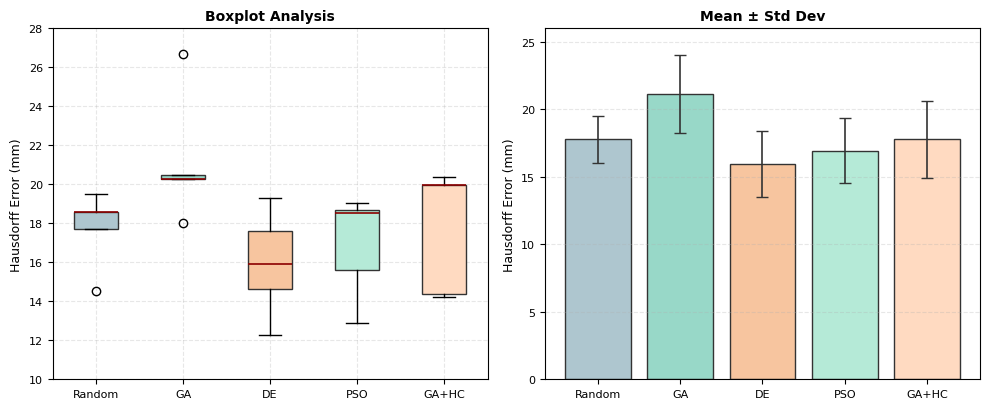

In [5]:
import os
import glob
import matplotlib.pyplot as plt
from numpy import arange, array

# 1. Sistema Automatizado de Nombre de Archivo
try:
    notebook_files = glob.glob("*.ipynb")
    if notebook_files:
        notebook_name = notebook_files[0].replace('.ipynb', '')
    else:
        notebook_name = "Figure_8.3_statistical_comparison"
except Exception:
    notebook_name = "Figure_8.3_statistical_comparison"

# 2. Configuración de calidad Springer (fuentes vectoriales y estilos)
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['ps.fonttype'] = 42
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Arial', 'Helvetica', 'DejaVu Sans']

# Ajuste de tamaño físico controlado (ancho de doble columna de Springer)
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
method_names = list(results_all.keys())
data = [results_all[m] for m in method_names]

# Colores profesionales discretos y elegantes estilo Springer
colors = ['#aec6cf', '#98d8c8', '#f7c59f', '#b5ead7', '#ffdac1']

# 3. Subplot izquierdo: Boxplot
bp = axes[0].boxplot(data, tick_labels=method_names, patch_artist=True,
                     medianprops=dict(color='darkred', linewidth=1.2))
for patch, c in zip(bp['boxes'], colors):
    patch.set_facecolor(c)
    patch.set_edgecolor('#333333')

axes[0].set_ylabel('Hausdorff Error (mm)', fontsize=9)
axes[0].set_title('Boxplot Analysis', fontsize=10, fontweight='bold')
axes[0].tick_params(labelsize=8)
axes[0].grid(True, alpha=0.3, linestyle='--')
# Margen de seguridad superior para prevenir solapamientos
axes[0].set_ylim(bottom=10, top=28)

# 4. Subplot derecho: Bar chart with error bars
means = array([results_all[m].mean() for m in method_names])
stds = array([results_all[m].std() for m in method_names])
xp = arange(len(method_names))

axes[1].bar(xp, means, yerr=stds, capsize=4, color=colors, edgecolor='#333333', error_kw=dict(ecolor='#333333', lw=1.2))
axes[1].set_xticks(xp)
axes[1].set_xticklabels(method_names)
axes[1].set_ylabel('Hausdorff Error (mm)', fontsize=9)
axes[1].set_title('Mean ± Std Dev', fontsize=10, fontweight='bold')
axes[1].tick_params(labelsize=8)
axes[1].grid(True, alpha=0.3, axis='y', linestyle='--')
# Margen de seguridad superior
axes[1].set_ylim(bottom=0, top=26)

plt.tight_layout()

# 5. Exportación Doble Obligatoria
plt.savefig(f'{notebook_name}.pdf', format='pdf', bbox_inches='tight')
plt.savefig(f'{notebook_name}.png', format='png', dpi=600, bbox_inches='tight')
plt.show()